<a href="https://colab.research.google.com/github/Shiva2259839/Mapping-Arc/blob/main/aravalli_sample_map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install geopandas cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 42.4 MB/s  0:00:00


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


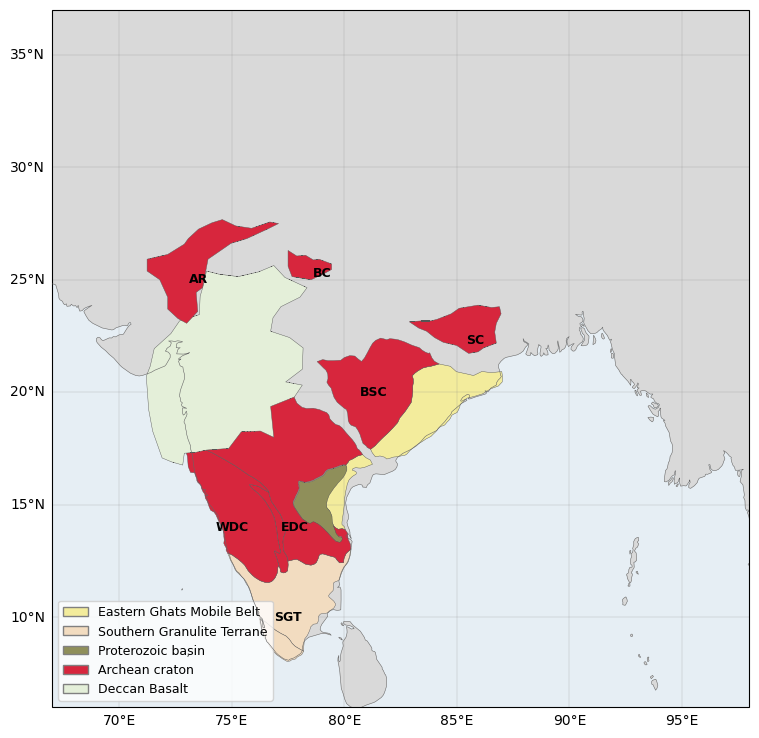

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

pc = ccrs.PlateCarree()
gprv = gpd.read_file("global_gprv.shp").to_crs("EPSG:4326")
traced = gpd.read_file("india_units.geojson").set_crs("EPSG:4326", allow_override=True)

def hast(names):
    return gprv[gprv["prov_name"].isin(names)].geometry

def mine(word):
    return traced[traced["name"].str.lower().str.contains(word)].geometry

fig = plt.figure(figsize=(9, 10))
ax = plt.axes(projection=pc)
ax.set_extent([67, 98, 6, 37], crs=pc)
ax.add_feature(cfeature.OCEAN, facecolor="#e6eef4", zorder=0)
ax.add_feature(cfeature.LAND, facecolor="#d9d9d9", zorder=1)

layers = [
    (hast(["Eastern Ghats Belt", "Krishna Province"]), "#f3ec9c", "Eastern Ghats Mobile Belt"),
    (hast(["Southern Granulite Terrane", "Trivandrum-Nagercoil Block"]), "#f2dcc0", "Southern Granulite Terrane"),
    (hast(["Chuddapah Basin"]), "#8f8f5a", "Proterozoic basin"),
    (hast(["Bastar Craton", "Western Dharwar Craton", "Eastern Dharwar Craton",
           "Closepet Batholith"]), "#d7263d", "Archean craton"),
    (mine("deccan"), "#e4efd9", "Deccan Basalt"),
    (mine("aravalli"), "#d7263d", None),
    (mine("bundel"), "#d7263d", None),
    (mine("singh"), "#d7263d", None),
]
handles = []
for z, (geom, color, label) in enumerate(layers, start=2):
    ax.add_geometries(geom, crs=pc, facecolor=color,
                      edgecolor="#555555", linewidth=0.3, zorder=z)
    if label:
        handles.append(mpatches.Patch(facecolor=color, edgecolor="grey", label=label))

ax.add_feature(cfeature.COASTLINE, linewidth=0.4, edgecolor="#666666", zorder=20)

labels = {"AR": (73.5, 25), "BC": (79, 25.3), "SC": (85.8, 22.3), "BSC": (81.3, 20),
          "WDC": (75, 14), "EDC": (77.8, 14), "SGT": (77.5, 10)}
for t, (x, y) in labels.items():
    ax.text(x, y, t, transform=pc, fontsize=9, fontweight="bold",
            ha="center", va="center", zorder=21)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="grey", alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.legend(handles=handles, loc="lower left", fontsize=9, frameon=True)

plt.savefig("india_cratons_v2.png", dpi=600, bbox_inches="tight")
plt.savefig("india_cratons_v2.pdf", bbox_inches="tight")
plt.show()

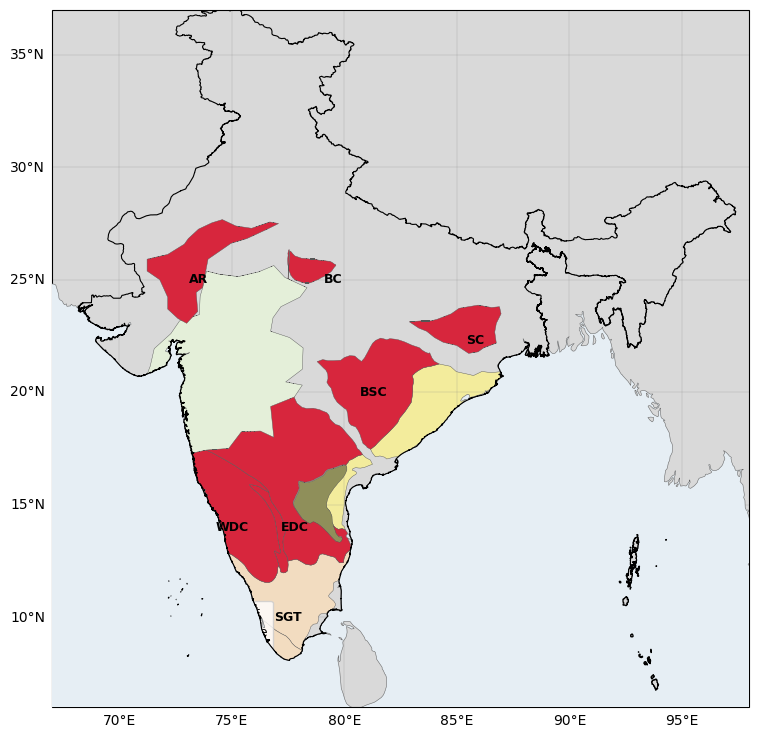

In [7]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from shapely.ops import unary_union

pc = ccrs.PlateCarree()
gprv = gpd.read_file("global_gprv.shp").to_crs("EPSG:4326")
traced = gpd.read_file("india_units.geojson").set_crs("EPSG:4326", allow_override=True)

land = unary_union(list(shpreader.Reader(
    shpreader.natural_earth("10m", "physical", "land")).geometries()))

def hast(names):
    return gprv[gprv["prov_name"].isin(names)].geometry

def mine(word, clip=False):
    g = traced[traced["name"].str.lower().str.contains(word)].geometry
    return g.intersection(land) if clip else g

fig = plt.figure(figsize=(9, 10))
ax = plt.axes(projection=pc)
ax.set_extent([67, 98, 6, 37], crs=pc)
ax.add_feature(cfeature.OCEAN, facecolor="#e6eef4", zorder=0)
ax.add_feature(cfeature.LAND, facecolor="#d9d9d9", zorder=1)

layers = [
    (hast(["Eastern Ghats Belt", "Krishna Province"]), "#f3ec9c", "Eastern Ghats Mobile Belt"),
    (hast(["Southern Granulite Terrane", "Trivandrum-Nagercoil Block"]), "#f2dcc0", "Southern Granulite Terrane"),
    (hast(["Chuddapah Basin"]), "#8f8f5a", "Proterozoic basin"),
        (hast(["Bastar Craton", "Western Dharwar Craton", "Eastern Dharwar Craton",
           "Closepet Batholith"]), "#d7263d", "Archean craton"),
    (mine("deccan"), "#e4efd9", "Deccan Basalt"),
    (mine("aravalli"), "#d7263d", None),
    (mine("bundel"), "#d7263d", None),
    (mine("singh"), "#d7263d", None),
]
handles = []
for z, (geom, color, label) in enumerate(layers, start=2):
    ax.add_geometries(geom, crs=pc, facecolor=color,
                      edgecolor="#555555", linewidth=0.3, zorder=z)
    if label:
        handles.append(mpatches.Patch(facecolor=color, edgecolor="grey", label=label))
ax.add_feature(cfeature.OCEAN, facecolor="#e6eef4", zorder=15)
ax.add_feature(cfeature.COASTLINE, linewidth=0.4, edgecolor="#666666", zorder=20)
india = gpd.read_file("https://raw.githubusercontent.com/datameet/maps/master/Country/india-composite.geojson").to_crs("EPSG:4326")
ax.add_geometries(india.geometry, crs=pc, facecolor="none",
                  edgecolor="black", linewidth=0.8, zorder=22)

labels = {"AR": (73.5, 25), "BC": (79.5, 25), "SC": (85.8, 22.3), "BSC": (81.3, 20),
          "WDC": (75, 14), "EDC": (77.8, 14), "SGT": (77.5, 10)}
for t, (x, y) in labels.items():
    ax.text(x, y, t, transform=pc, fontsize=9, fontweight="bold",
            ha="center", va="center", zorder=21)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="grey", alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.legend(handles=handles, loc="lower left", fontsize=9, frameon=True)

plt.savefig("india_cratons_v2.png", dpi=600, bbox_inches="tight")
plt.savefig("india_cratons_v2.pdf", bbox_inches="tight")
plt.show()

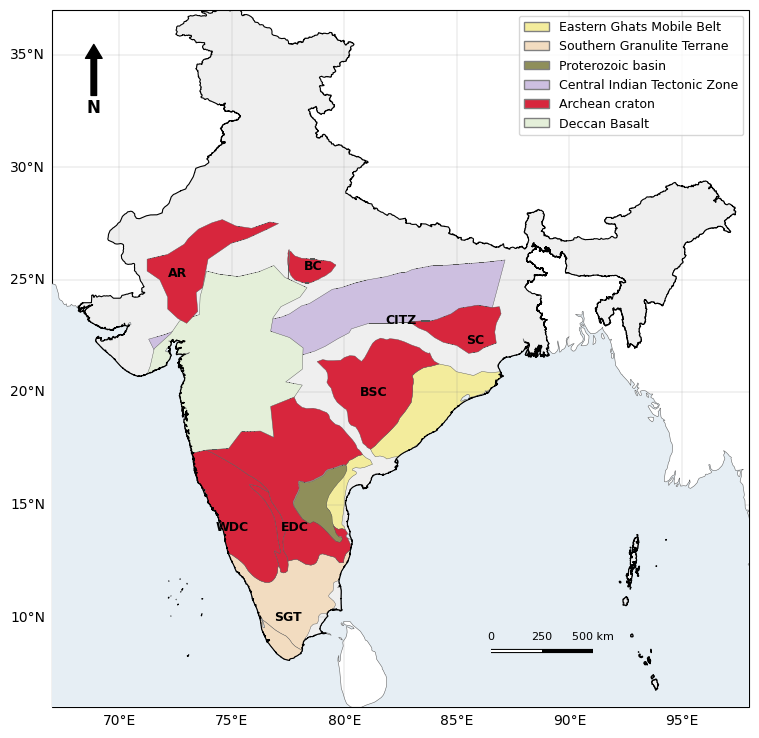

In [20]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.ops import unary_union

pc = ccrs.PlateCarree()
gprv = gpd.read_file("global_gprv.shp").to_crs("EPSG:4326")
traced = gpd.read_file("india_units.geojson").set_crs("EPSG:4326", allow_override=True)
india = gpd.read_file("https://raw.githubusercontent.com/datameet/maps/master/Country/india-composite.geojson").to_crs("EPSG:4326")

def hast(names):
    return gprv[gprv["prov_name"].isin(names)].geometry

def mine(word):
    return traced[traced["name"].str.lower().str.contains(word)].geometry

fig = plt.figure(figsize=(9, 10))
ax = plt.axes(projection=pc)
ax.set_extent([67, 98, 6, 37], crs=pc)

# Pehle samundar, phir bahar ki zameen safed, phir India halke rang me
ax.add_feature(cfeature.OCEAN, facecolor="#e6eef4", zorder=0)
ax.add_feature(cfeature.LAND, facecolor="white", zorder=1)
ax.add_geometries(india.geometry, crs=pc, facecolor="#efefef",
                  edgecolor="none", zorder=1.5)

layers = [
    (hast(["Eastern Ghats Belt", "Krishna Province"]), "#f3ec9c", "Eastern Ghats Mobile Belt"),
    (hast(["Southern Granulite Terrane", "Trivandrum-Nagercoil Block"]), "#f2dcc0", "Southern Granulite Terrane"),
    (hast(["Chuddapah Basin"]), "#8f8f5a", "Proterozoic basin"),
        (mine("citz"), "#cdbfe0", "Central Indian Tectonic Zone"),
    (hast(["Bastar Craton", "Western Dharwar Craton", "Eastern Dharwar Craton",
           "Closepet Batholith"]).difference(unary_union(mine("deccan"))), "#d7263d", "Archean craton"),
    (mine("deccan"), "#e4efd9", "Deccan Basalt"),
    (mine("aravalli"), "#d7263d", None),
    (mine("bundel"), "#d7263d", None),
    (mine("singh"), "#d7263d", None),
]
handles = []
for z, (geom, color, label) in enumerate(layers, start=2):
    ax.add_geometries(geom, crs=pc, facecolor=color,
                      edgecolor="#555555", linewidth=0.3, zorder=z)
    if label:
        handles.append(mpatches.Patch(facecolor=color, edgecolor="grey", label=label))

# Samundar dobara upar, taaki Deccan paani me na dikhe
ax.add_feature(cfeature.OCEAN, facecolor="#e6eef4", zorder=15)
ax.add_feature(cfeature.COASTLINE, linewidth=0.4, edgecolor="#666666", zorder=20)
ax.add_geometries(india.geometry, crs=pc, facecolor="none",
                  edgecolor="black", linewidth=0.8, zorder=22)

labels = {"AR": (72.6, 25.3), "BC": (78.6, 25.6), "SC": (85.8, 22.3), "BSC": (81.3, 20),
          "WDC": (75, 14), "EDC": (77.8, 14), "SGT": (77.5, 10), "CITZ": (82.5, 23.2)}
for t, (x, y) in labels.items():
    ax.text(x, y, t, transform=pc, fontsize=9, fontweight="bold",
            ha="center", va="center", zorder=23)

gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="grey", alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.legend(handles=handles, loc="upper right", fontsize=9, frameon=True).set_zorder(30)
import numpy as np

# --- Scale bar: 500 km, neeche daayein samundar me ---
lat0, lon0, km = 8.5, 86.5, 500
dlon = km / (111.32 * np.cos(np.radians(lat0)))
ax.plot([lon0, lon0 + dlon], [lat0, lat0], color="black", linewidth=3,
        transform=pc, zorder=25, solid_capstyle="butt")
ax.plot([lon0, lon0 + dlon/2], [lat0, lat0], color="white", linewidth=1.5,
        transform=pc, zorder=26, solid_capstyle="butt")
for x, t in [(lon0, "0"), (lon0 + dlon/2, "250"), (lon0 + dlon, "500 km")]:
    ax.text(x, lat0 + 0.5, t, transform=pc, ha="center", fontsize=8, zorder=26)

# --- North arrow: upar daayein kone me ---
ax.annotate("N", xy=(0.06, 0.95), xytext=(0.06, 0.86), xycoords="axes fraction",
            ha="center", va="center", fontsize=12, fontweight="bold", zorder=27,
            arrowprops=dict(facecolor="black", width=4, headwidth=12, headlength=10))

plt.savefig("india_cratons_v3.png", dpi=600, bbox_inches="tight")
plt.savefig("india_cratons_v3.pdf", bbox_inches="tight")
plt.show()

In [23]:
!pip install geopandas cartopy

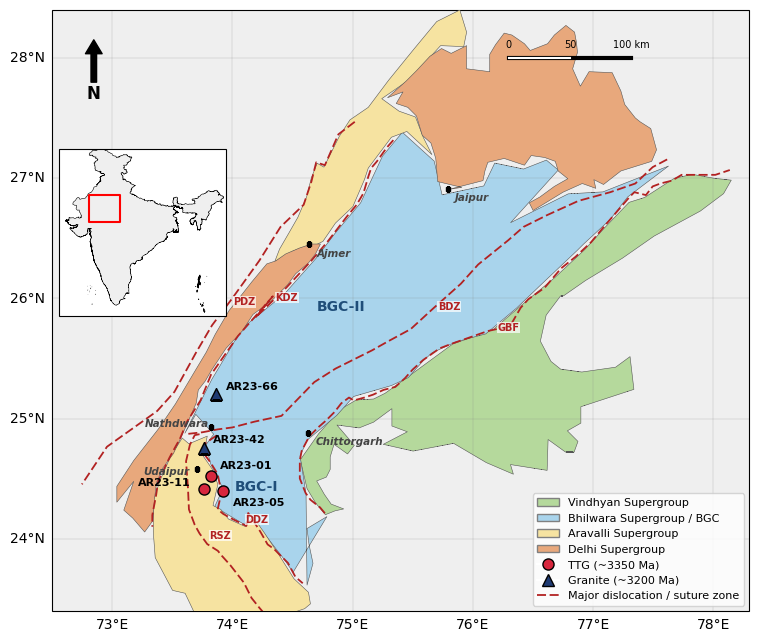

In [35]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature

pc = ccrs.PlateCarree()
units = gpd.read_file("aravalli_units.geojson").set_crs("EPSG:4326", allow_override=True)
india = gpd.read_file("https://raw.githubusercontent.com/datameet/maps/master/Country/india-composite.geojson").to_crs("EPSG:4326")

def get(word):
    return units[units["name"].str.lower().str.contains(word)].geometry

fig = plt.figure(figsize=(9, 10))
ax = plt.axes(projection=pc)
ax.set_extent([72.5, 78.3, 23.4, 28.4], crs=pc)
ax.add_feature(cfeature.LAND, facecolor="white", zorder=0)
ax.add_geometries(india.geometry, crs=pc, facecolor="#efefef", edgecolor="none", zorder=0.5)

layers = [
    (get("vindhyan"), "#b5d99c", "Vindhyan Supergroup"),
    (get("bhilwara"), "#a9d4ec", "Bhilwara Supergroup / BGC"),
    (get("aravalli"), "#f6e3a1", "Aravalli Supergroup"),
    (get("delhi"),    "#e8a87c", "Delhi Supergroup"),
]
handles = []
for z, (g, c, lab) in enumerate(layers, start=1):
    ax.add_geometries(g, crs=pc, facecolor=c, edgecolor="#555555", linewidth=0.4, zorder=z)
    handles.append(mpatches.Patch(facecolor=c, edgecolor="grey", label=lab))

samples = [
    ("AR23-01", 24.5266, 73.8189, "TTG"),
    ("AR23-11", 24.4180, 73.7628, "TTG"),
    ("AR23-05", 24.3997, 73.9232, "TTG"),
    ("AR23-42", 24.7587, 73.7622, "Granite"),
    ("AR23-66", 25.2037, 73.8658, "Granite"),
]
style = {"TTG": ("o", "#d7263d"), "Granite": ("^", "#1f3b73")}
offsets = {"AR23-01": (0.08, 0.06), "AR23-11": (-0.55, 0.02), "AR23-05": (0.08, -0.12),
           "AR23-42": (0.08, 0.04), "AR23-66": (0.08, 0.04)}
for name, lat, lon, kind in samples:
    m, c = style[kind]
    ax.plot(lon, lat, marker=m, color=c, markeredgecolor="black", markersize=8,
            transform=pc, zorder=20)
    dx, dy = offsets[name]
    ax.text(lon + dx, lat + dy, name, transform=pc, fontsize=8, fontweight="bold", zorder=21)

handles += [
    Line2D([], [], marker="o", color="w", markerfacecolor="#d7263d", markeredgecolor="black",
           markersize=8, label="TTG (~3350 Ma)"),
    Line2D([], [], marker="^", color="w", markerfacecolor="#1f3b73", markeredgecolor="black",
           markersize=8, label="Granite (~3200 Ma)"),
]

towns = {"Udaipur": (73.71, 24.58), "Ajmer": (74.64, 26.45), "Jaipur": (75.79, 26.91),
         "Chittorgarh": (74.63, 24.88), "Nathdwara": (73.82, 24.93)}
for t, (x, y) in towns.items():
    ax.plot(x, y, "ks", markersize=3, transform=pc, zorder=18)
    dx, dy = {"Udaipur": (-0.45, -0.05), "Nathdwara": (-0.55, 0.0)}.get(t, (0.06, -0.1))
    ax.text(x + dx, y + dy, t, transform=pc, fontsize=7.5, style="italic",
            fontweight="semibold", color="#444444", zorder=18)
# --- Faults / dislocation zones ---
lines = gpd.read_file("aravalli_lines.geojson").set_crs("EPSG:4326", allow_override=True)
for _, row in lines.iterrows():
    g = row.geometry
    ax.add_geometries([g], crs=pc, facecolor="none", edgecolor="#b22222",
                      linewidth=1.3, linestyle=(0, (5, 2)), zorder=15)
    mid = g.interpolate(0.5, normalized=True)
    ax.text(mid.x + 0.05, mid.y, row["name"], transform=pc, fontsize=7,
            fontweight="bold", color="#b22222", zorder=16,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.5))

handles.append(Line2D([], [], color="#b22222", linewidth=1.3, linestyle=(0, (5, 2)),
                      label="Major dislocation / suture zone"))

# --- BGC labels ---
for lab, (x, y) in {"BGC-I": (74.2, 24.4), "BGC-II": (74.9, 25.9)}.items():
    ax.text(x, y, lab, transform=pc, fontsize=10, fontweight="bold",
            color="#1f4e79", ha="center", zorder=17)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="grey", alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.legend(handles=handles, loc="lower right", fontsize=8, frameon=True).set_zorder(30)

lat0, lon0, km = 28.0, 76.3, 100
dlon = km / (111.32 * np.cos(np.radians(lat0)))
ax.plot([lon0, lon0 + dlon], [lat0, lat0], color="black", linewidth=3, transform=pc, zorder=25)
ax.plot([lon0, lon0 + dlon/2], [lat0, lat0], color="white", linewidth=1.5, transform=pc, zorder=26)
for x, t in [(lon0, "0"), (lon0 + dlon/2, "50"), (lon0 + dlon, "100 km")]:
    ax.text(x, lat0 + 0.08, t, transform=pc, ha="center", fontsize=7, zorder=26)

ax.annotate("N", xy=(0.06, 0.95), xytext=(0.06, 0.86), xycoords="axes fraction",
            ha="center", va="center", fontsize=12, fontweight="bold", zorder=27,
            arrowprops=dict(facecolor="black", width=4, headwidth=12, headlength=10))

ins = ax.inset_axes([0.01, 0.45, 0.24, 0.36], projection=pc)
ins.set_extent([67, 98, 6, 37], crs=pc)
ins.add_geometries(india.geometry, crs=pc, facecolor="#efefef", edgecolor="black", linewidth=0.4)
from shapely.geometry import box
ins.add_geometries([box(72.5, 23.4, 78.3, 28.4)], crs=pc, facecolor="none",
                   edgecolor="red", linewidth=1.5, zorder=5)
ins.set_zorder(30)

plt.savefig("aravalli_samples.png", dpi=600, bbox_inches="tight")
plt.savefig("aravalli_samples.pdf", bbox_inches="tight")
plt.show()